Total records: 200


,passenger_id,survived,pclass,sex,age,fare,embarked,cabin
0,1,0,3,male,NaN,3.37,S,NaN
1,2,1,3,male,56.0,17.67,C,NaN
2,3,0,3,male,28.0,8.20,S,NaN
3,4,0,1,male,33.0,169.28,S,F33
4,5,1,3,male,61.0,11.46,S,NaN
5,6,1,3,male,6.0,24.45,NaN,NaN
6,7,0,2,female,37.0,4.81,S,NaN
7,8,0,1,male,NaN,21.28,C,NaN
8,9,0,3,male,66.0,28.49,S,NaN
9,10,1,3,male,63.0,15.15,S,D10


Shape: (200, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   passenger_id  200 non-null    int64  
 1   survived      200 non-null    int64  
 2   pclass        200 non-null    int64  
 3   sex           200 non-null    object 
 4   age           158 non-null    float64
 5   fare          196 non-null    float64
 6   embarked      198 non-null    object 
 7   cabin         45 non-null     object 
dtypes: float64(2), int64(3), object(3)
memory usage: 12.6+ KB


,missing_count,missing_percent
cabin,155,77.5
age,42,21.0
fare,4,2.0
embarked,2,1.0
sex,0,0.0
pclass,0,0.0
survived,0,0.0
passenger_id,0,0.0


Total missing cells: 203
Rows with at least one missing value: 163 of 200


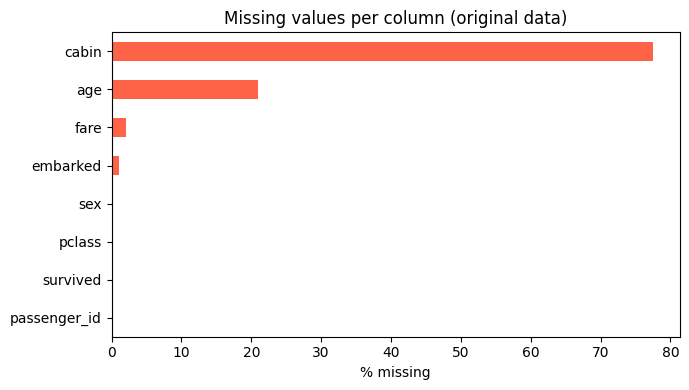

Rows before dropna(): 200
Rows after  dropna(): 37
Data lost: 82%  -> too much, so we avoid blind dropna()
Age: mean   = 32.97
Age: median = 30.0
Age: skew   = 0.71 (positive = right-skewed, a few very old passengers)

Embarked value counts:
embarked
S      151
C       34
Q       13
NaN      2
Name: count, dtype: int64
Working on a copy. Original rows: 200 | Copy rows: 200
Columns now: ['passenger_id', 'survived', 'pclass', 'sex', 'age', 'fare', 'embarked']
Filled age with median = 30.0


,median fare by class
pclass,
1,81.80
2,31.24
3,13.46


Filled embarked with mode = S
Missing values after cleaning:
passenger_id    0
survived        0
pclass          0
sex             0
age             0
fare            0
embarked        0
dtype: int64

Total missing cells: 0
Rows kept: 200 of 200 (no rows were lost)


,before,after
count,158.00,200.00
mean,32.97,32.34
std,16.00,14.26
min,6.00,6.00
25%,21.00,24.00
50%,30.00,30.00
75%,41.75,38.00
max,80.00,80.00


,passenger_id,survived,pclass,sex,age,fare,embarked
0,1,0,3,male,30.0,3.37,S
1,2,1,3,male,56.0,17.67,C
2,3,0,3,male,28.0,8.20,S
3,4,0,1,male,33.0,169.28,S
4,5,1,3,male,61.0,11.46,S
5,6,1,3,male,6.0,24.45,S
6,7,0,2,female,37.0,4.81,S
7,8,0,1,male,30.0,21.28,C
8,9,0,3,male,66.0,28.49,S
9,10,1,3,male,63.0,15.15,S


Saved passengers_cleaned.csv


,column,missing %,method,reason
0,cabin,77.5,Drop column,Too many missing values to fill reliably
1,age,21.0,Fill with median,"Skewed numerical data, median ignores extremes"
2,fare,2.0,Fill with median per pclass,Fare depends strongly on passenger class
3,embarked,1.0,Fill with mode,"Categorical column, only 2 rows missing"


OBSERVATIONS
--------------------------------------------------
1. The original data had 203 missing cells in 4 columns.
2. A blind dropna() would have deleted 163 of 200 rows, so each column was treated separately.
3. After cleaning, there are 0 missing values and all rows were kept.


In [1]:
# ===== Task 21: Handle Missing Values (Pandas) =====
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# ---------- 1. Create and load the dataset (contains missing values) ----------
rng = np.random.default_rng(21)
n = 200

pclass = rng.choice([1, 2, 3], n, p=[0.25, 0.20, 0.55])
sex = rng.choice(['male', 'female'], n, p=[0.64, 0.36])
age = np.clip(rng.gamma(4, 7.5, n) + 1, 1, 80).round(0)                # right-skewed ages
fare = (rng.gamma(2, 1, n) * np.select([pclass == 1, pclass == 2], [45, 20], 8)).round(2)
embarked = rng.choice(['S', 'C', 'Q'], n, p=[0.72, 0.19, 0.09])
cabin = rng.choice(['A12', 'B22', 'C85', 'D10', 'E46', 'F33'], n)
surv_prob = np.where(sex == 'female', 0.75, 0.2) + np.where(pclass == 1, 0.15, 0)
survived = (rng.random(n) < surv_prob).astype(int)

data = pd.DataFrame({
    'passenger_id': np.arange(1, n + 1),
    'survived': survived,
    'pclass': pclass,
    'sex': sex,
    'age': age,
    'fare': fare,
    'embarked': embarked,
    'cabin': cabin})

# put missing values in, like real-world data
data.loc[rng.random(n) < 0.20, 'age'] = np.nan                          # about 20% of ages missing
data.loc[rng.choice(n, 4, replace=False), 'fare'] = np.nan              # 4 fares missing
data.loc[rng.choice(n, 2, replace=False), 'embarked'] = np.nan         # 2 ports missing
data.loc[(pclass != 1) & (rng.random(n) < 0.95), 'cabin'] = np.nan      # cabin mostly missing
data.loc[(pclass == 1) & (rng.random(n) < 0.20), 'cabin'] = np.nan

data.to_csv('passengers.csv', index=False)
df = pd.read_csv('passengers.csv')
print('Total records:', len(df))
display(df.head(10))

# ---------- 2. Dataset overview ----------
print('Shape:', df.shape)
print()
df.info()

# ---------- Part A: Original missing-value analysis ----------
# A1. Count and percentage of missing values per column
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_percent': (df.isnull().mean() * 100).round(1)})
missing = missing.sort_values('missing_percent', ascending=False)
display(missing)
print('Total missing cells:', int(df.isnull().sum().sum()))
print('Rows with at least one missing value:', int(df.isnull().any(axis=1).sum()), 'of', len(df))

# A2. Visualize the missing values
ax = (df.isnull().mean() * 100).sort_values().plot(kind='barh', color='tomato', figsize=(7, 4))
ax.set_xlabel('% missing')
ax.set_title('Missing values per column (original data)')
plt.tight_layout()
plt.show()

# A3. What would a blind dropna() do?
after_drop = df.dropna()
print('Rows before dropna():', len(df))
print('Rows after  dropna():', len(after_drop))
print(f'Data lost: {(1 - len(after_drop) / len(df)) * 100:.0f}%  -> too much, so we avoid blind dropna()')

# A4. Look at the data before choosing a method
print('Age: mean   =', round(df['age'].mean(), 2))
print('Age: median =', df['age'].median())
print('Age: skew   =', round(df['age'].skew(), 2), '(positive = right-skewed, a few very old passengers)')
print()
print('Embarked value counts:')
print(df['embarked'].value_counts(dropna=False))

# ---------- Part B: Cleaning (on a copy, so the original is kept) ----------
df_clean = df.copy()
print('Working on a copy. Original rows:', len(df), '| Copy rows:', len(df_clean))

# B1. cabin (about 77% missing): DROP THE COLUMN
# Why: with most values missing, filling would invent data and the column carries little information.
df_clean = df_clean.drop(columns=['cabin'])
print('Columns now:', list(df_clean.columns))

# B2. age (about 21% missing, numerical and skewed): fill with the MEDIAN
# Why: age is right-skewed, so the mean is pulled up by a few very old passengers; the median is not.
age_median = df_clean['age'].median()
df_clean['age'] = df_clean['age'].fillna(age_median)
print('Filled age with median =', age_median)

# B3. fare (few missing, depends on class): fill with the MEDIAN OF EACH PASSENGER CLASS
# Why: fares differ a lot between 1st, 2nd and 3rd class, so one overall value would be unfair.
display(df_clean.groupby('pclass')['fare'].median().round(2).rename('median fare by class'))
df_clean['fare'] = df_clean['fare'].fillna(df_clean.groupby('pclass')['fare'].transform('median'))

# B4. embarked (only 2 missing, categorical): fill with the MODE (most frequent value)
# Why: a category has no mean or median; the most common port is the most likely value.
port_mode = df_clean['embarked'].mode()[0]
df_clean['embarked'] = df_clean['embarked'].fillna(port_mode)
print('Filled embarked with mode =', port_mode)

# ---------- Part C: Verify the cleaned dataset ----------
print('Missing values after cleaning:')
print(df_clean.isnull().sum())
print()
print('Total missing cells:', int(df_clean.isnull().sum().sum()))
print('Rows kept:', len(df_clean), 'of', len(df), '(no rows were lost)')

# Before vs after: did the age distribution change a lot?
compare = pd.DataFrame({'before': df['age'].describe(), 'after': df_clean['age'].describe()}).round(2)
display(compare)

# Cleaned dataset
display(df_clean.head(10))
df_clean.to_csv('passengers_cleaned.csv', index=False)
print('Saved passengers_cleaned.csv')

# ---------- Summary: method chosen and why ----------
summary = pd.DataFrame({
    'column': ['cabin', 'age', 'fare', 'embarked'],
    'missing %': [round(df[c].isnull().mean() * 100, 1) for c in ['cabin', 'age', 'fare', 'embarked']],
    'method': ['Drop column', 'Fill with median', 'Fill with median per pclass', 'Fill with mode'],
    'reason': ['Too many missing values to fill reliably',
               'Skewed numerical data, median ignores extremes',
               'Fare depends strongly on passenger class',
               'Categorical column, only 2 rows missing']})
display(summary)

# ---------- Observations ----------
print('OBSERVATIONS')
print('-' * 50)
print(f"1. The original data had {int(df.isnull().sum().sum())} missing cells in {df.isnull().any().sum()} columns.")
print(f"2. A blind dropna() would have deleted {len(df) - len(after_drop)} of {len(df)} rows, so each column was treated separately.")
print('3. After cleaning, there are 0 missing values and all rows were kept.')